In [9]:
print("hello world")

hello world


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Class Balance:
y
no     29229
yes     3711
Name: count, dtype: int64
y
no     0.887341
yes    0.112659
Name: proportion, dtype: float64

Missing ('unknown') values in Train:
job           275
marital        64
education    1401
default      6871
housing       794
loan          794
dtype: int64

Sentinel pdays == 999 count:
31694


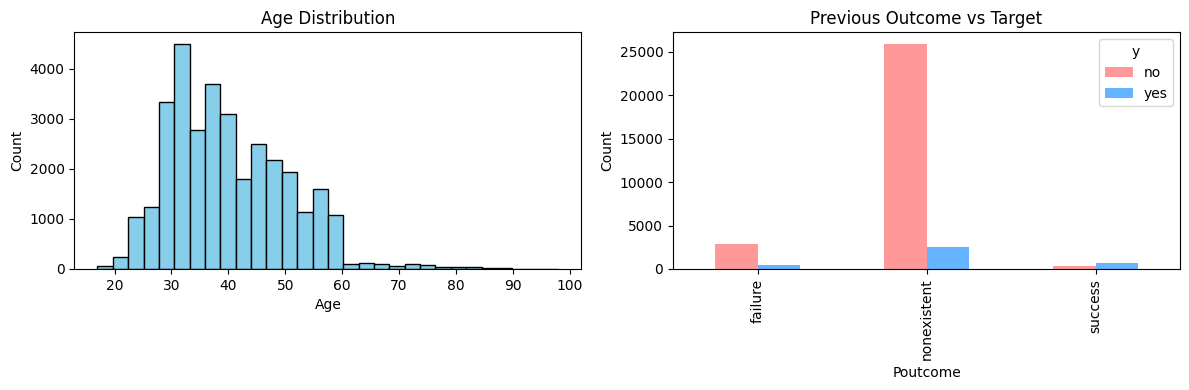

In [11]:
train = pd.read_csv('data/train.csv')
test = pd.read_csv('data/test.csv')

print("Class Balance:")
print(train['y'].value_counts())
print(train['y'].value_counts(normalize=True))

print("\nMissing ('unknown') values in Train:")
print((train == 'unknown').sum()[(train == 'unknown').sum() > 0])

print("\nSentinel pdays == 999 count:")
print((train['pdays'] == 999).sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(train['age'], bins=30, color='skyblue', edgecolor='black')
axes[0].set_title('Age Distribution')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Count')


poutcome_y = pd.crosstab(train['poutcome'], train['y'])
poutcome_y.plot(kind='bar', ax=axes[1], color=['#ff9999', '#66b3ff'])
axes[1].set_title('Previous Outcome vs Target')
axes[1].set_xlabel('Poutcome')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

In [12]:
import sys
import sklearn
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

SEED = 42
print(f"Python version: {sys.version}")
print(f"Scikit-learn version: {sklearn.__version__}")

y = (train['y'] == 'yes').astype(int)
X = train.drop(columns=['id', 'y', 'duration'])

X_dev, X_holdout, y_dev, y_holdout = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

num_cols = X_dev.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_dev.select_dtypes(include=['object']).columns.tolist()

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='unknown')),
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

dummy_pipe = Pipeline([('prep', preprocessor), ('model', DummyClassifier(strategy='prior'))])
dummy_res = cross_validate(dummy_pipe, X_dev, y_dev, cv=cv, scoring=['accuracy', 'roc_auc'])

print(f"Majority Baseline Accuracy: {dummy_res['test_accuracy'].mean():.4f} (+/- {dummy_res['test_accuracy'].std():.4f})")
print(f"Majority Baseline ROC-AUC:  {dummy_res['test_roc_auc'].mean():.4f} (+/- {dummy_res['test_roc_auc'].std():.4f})")

simple_pipe = Pipeline([('prep', preprocessor), ('model', LogisticRegression(max_iter=1000, random_state=SEED))])
simple_res = cross_validate(simple_pipe, X_dev, y_dev, cv=cv, scoring=['accuracy', 'roc_auc'])

print(f"Simple LogReg Accuracy:     {simple_res['test_accuracy'].mean():.4f} (+/- {simple_res['test_accuracy'].std():.4f})")
print(f"Simple LogReg ROC-AUC:      {simple_res['test_roc_auc'].mean():.4f} (+/- {simple_res['test_roc_auc'].std():.4f})")


Python version: 3.12.3 (v3.12.3:f6650f9ad7, Apr  9 2024, 08:18:47) [Clang 13.0.0 (clang-1300.0.29.30)]
Scikit-learn version: 1.7.2
Majority Baseline Accuracy: 0.8873 (+/- 0.0001)
Majority Baseline ROC-AUC:  0.5000 (+/- 0.0000)
Simple LogReg Accuracy:     0.9007 (+/- 0.0008)
Simple LogReg ROC-AUC:      0.7964 (+/- 0.0074)


In [14]:
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

models = {
    'LogReg': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED),
    'RandomForest': RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=SEED),
    'GradBoost': GradientBoostingClassifier(n_estimators=150, random_state=SEED)
}

for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    scores = cross_val_score(pipe, X_dev, y_dev, cv=cv, scoring='roc_auc')
    print(f"{name:<15} ROC-AUC: {scores.mean():.4f} (+/- {scores.std():.4f})")

pipe_unbalanced = Pipeline([('prep', preprocessor), ('model', LogisticRegression(max_iter=1000, random_state=SEED))])
score_unbalanced = cross_val_score(pipe_unbalanced, X_dev, y_dev, cv=cv, scoring='roc_auc').mean()

pipe_balanced = Pipeline([('prep', preprocessor), ('model', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED))])
score_balanced = cross_val_score(pipe_balanced, X_dev, y_dev, cv=cv, scoring='roc_auc').mean()

print(f"\nClass Weight None ROC-AUC:     {score_unbalanced:.4f}")
print(f"Class Weight Balanced ROC-AUC: {score_balanced:.4f}")

param_grid = {
    'model__n_estimators': [100, 200],
    'model__learning_rate': [0.05, 0.1],
    'model__max_depth': [3, 5]
}

gb_pipe = Pipeline([('prep', preprocessor), ('model', GradientBoostingClassifier(random_state=SEED))])
grid_search = GridSearchCV(gb_pipe, param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_search.fit(X_dev, y_dev)

print(f"\nBest Params: {grid_search.best_params_}")
print(f"Best Tuned ROC-AUC: {grid_search.best_score_:.4f}")


LogReg          ROC-AUC: 0.7976 (+/- 0.0065)
RandomForest    ROC-AUC: 0.7766 (+/- 0.0063)
GradBoost       ROC-AUC: 0.8039 (+/- 0.0057)

Class Weight None ROC-AUC:     0.7964
Class Weight Balanced ROC-AUC: 0.7976

Best Params: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}
Best Tuned ROC-AUC: 0.8039


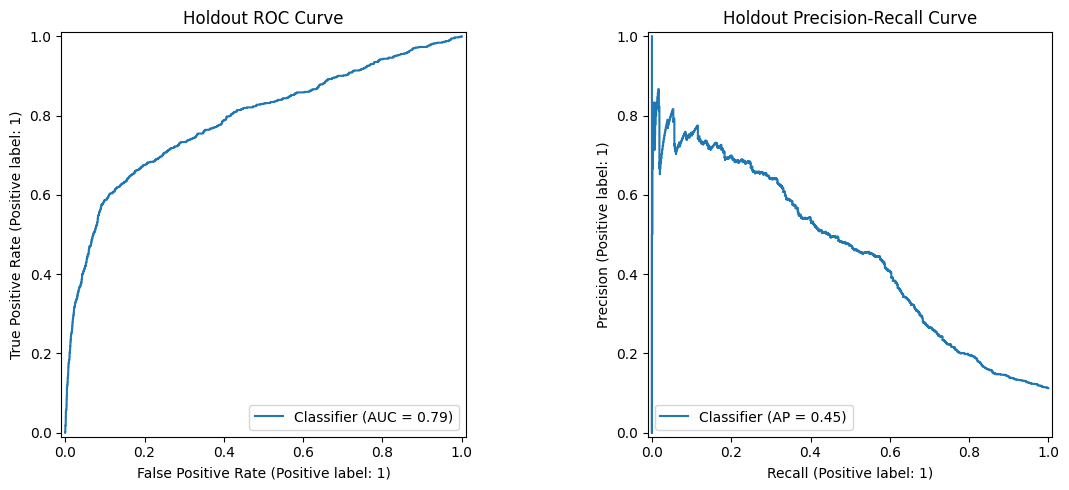

Cutoff threshold (10% capacity): 0.3260
Precision at top 10%: 0.5008
Recall at top 10%:    0.4447
Lift over random:     4.45x

Confusion Matrix at 10% cutoff:
[[5517  329]
 [ 412  330]]


In [15]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, confusion_matrix, precision_score, recall_score

best_model = grid_search.best_estimator_

y_proba_holdout = best_model.predict_proba(X_holdout)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_holdout, y_proba_holdout, ax=axes[0])
axes[0].set_title('Holdout ROC Curve')

PrecisionRecallDisplay.from_predictions(y_holdout, y_proba_holdout, ax=axes[1])
axes[1].set_title('Holdout Precision-Recall Curve')
plt.tight_layout()
plt.show()

cutoff = np.percentile(y_proba_holdout, 90)
y_pred_10 = (y_proba_holdout >= cutoff).astype(int)

prec = precision_score(y_holdout, y_pred_10)
rec = recall_score(y_holdout, y_pred_10)
random_prec = y_holdout.mean()
lift = prec / random_prec

print(f"Cutoff threshold (10% capacity): {cutoff:.4f}")
print(f"Precision at top 10%: {prec:.4f}")
print(f"Recall at top 10%:    {rec:.4f}")
print(f"Lift over random:     {lift:.2f}x")

cm = confusion_matrix(y_holdout, y_pred_10)
print("\nConfusion Matrix at 10% cutoff:")
print(cm)


In [16]:
best_model.fit(X, y)

joblib.dump(best_model, 'model.joblib')
print("Model saved to model.joblib")

loaded_model = joblib.load('model.joblib')

test_raw = pd.read_csv('data/test.csv')
X_test_raw = test_raw.drop(columns=['id'])

test_proba = loaded_model.predict_proba(X_test_raw)[:, 1]
test_pred = (test_proba >= cutoff).astype(int)

predictions = pd.DataFrame({
    'id': test_raw['id'],
    'y_pred': test_pred,
    'y_score': test_proba
})

predictions.to_csv('predictions.csv', index=False)
print("predictions.csv created successfully!")
print(predictions.head())


Model saved to model.joblib
predictions.csv created successfully!
      id  y_pred   y_score
0  32940       0  0.045856
1  32941       0  0.032310
2  32942       0  0.049168
3  32943       0  0.083360
4  32944       0  0.055334
